# Analyse des accidents d'aviation

Vous faites partie d'un cabinet de conseil chargé de réaliser une analyse de la sécurité des avions de ligne commerciaux et de transport de passagers. Le client (un assureur de compagnies aériennes/d'avions) souhaite savoir quels types d'appareils (marques/modèles) présentent de faibles taux de destruction totale et une faible probabilité de blessures mortelles ou graves pour les passagers en cas d'accident. Il s'intéresse aussi à toutes les variables/conditions générales susceptibles d'entrer en jeu. Votre analyse reposera sur des données d'accidents d'aviation accumulées de 1948 à 2023.

Notre client ne s'intéresse qu'aux marques/modèles d'avions de construction professionnelle et susceptibles d'être encore en service. Supposez une durée de vie maximale de 40 ans avant le retrait d'une marque/d'un modèle et filtrez vos données en conséquence (c'est-à-dire à partir de 1983). Il souhaite également des recommandations distinctes pour les petits appareils et pour les modèles de passagers plus grands. **De plus, assurez-vous que vos affirmations sont statistiquement solides et que vous disposez d'assez d'échantillons pour comparer des groupes.**


Dans cette évaluation sommative, vous démontrerez votre capacité à :
- **Utiliser Pandas pour charger, inspecter et nettoyer correctement le jeu de données.**
- **Transformer les colonnes pertinentes pour créer des mesures répondant au problème posé.**
- mener une analyse exploratoire (EDA) : visualisations et mesures statistiques pour comprendre systématiquement la structure des données
- recommander un ensemble d'avions et de marques conformes à la demande du client et identifier au moins *deux* facteurs contribuant à la sécurité des avions. Vous devez fournir des preuves à l'appui (visuels, statistiques descriptives, tableaux) pour chaque affirmation que vous faites.

### Effectuer les importations de bibliothèques nécessaires

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Chargement et inspection des données

### Chargez les données depuis le répertoire approprié et inspectez le DataFrame.
- inspectez les NaN, les types de données et les statistiques descriptives

In [ ]:
aviation_df = pd.read_csv("data/AviationData.csv", encoding = "latin1", low_memory = False)
aviation_df["Event.Date"] = pd.to_datetime(aviation_df["Event.Date"])

aviation_df = aviation_df[aviation_df["Event.Date"].dt.year >= 1983]


**Note :** au debut j'avais mis `> (2023 - 40)`, mais ca enleve l'annee 1983 alors que la consigne dit "a partir de 1983". J'ai donc mis `>= 1983`.

Ensuite on regarde la taille du tableau, les types de donnees et quelques statistiques.

In [ ]:
print(aviation_df.shape)
aviation_df.head()

(85289, 31)


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Purpose.of.flight,Air.carrier,Total.Fatal.Injuries,Total.Serious.Injuries,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Report.Status,Publication.Date
3600,20001214X42040,Accident,LAX83LA093,1983-01-01,"ARROYO GRANDE, CA",United States,NaN,NaN,NaN,NaN,...,Personal,NaN,0.0,1.0,0.0,1.0,VMC,Landing,Probable Cause,NaN
3601,20001214X42095,Accident,SEA83LA036,1983-01-01,"NEWPORT, OR",United States,NaN,NaN,ONP,NEWPORT MUNICIPAL,...,Personal,NaN,0.0,0.0,1.0,3.0,VMC,Approach,Probable Cause,NaN
3602,20001214X42067,Accident,MKC83LA056,1983-01-01,"WOODBINE, IA",United States,NaN,NaN,3YR,MUNICIPAL,...,Personal,NaN,0.0,0.0,0.0,2.0,VMC,Landing,Probable Cause,NaN
3603,20001214X42063,Accident,MKC83LA050,1983-01-01,"MARYVILLE, MO",United States,NaN,NaN,78Y,RANKIN,...,Personal,NaN,0.0,0.0,0.0,1.0,VMC,Takeoff,Probable Cause,NaN
3604,20001214X42018,Accident,LAX83FUG11,1983-01-01,"UPLAND, CA",United States,NaN,NaN,CCB,CABLE,...,Personal,NaN,0.0,0.0,2.0,0.0,VMC,Approach,Probable Cause,NaN


In [ ]:
aviation_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 85289 entries, 3600 to 88888
Data columns (total 31 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Event.Id                85289 non-null  object        
 1   Investigation.Type      85289 non-null  object        
 2   Accident.Number         85289 non-null  object        
 3   Event.Date              85289 non-null  datetime64[ns]
 4   Location                85237 non-null  object        
 5   Country                 85073 non-null  object        
 6   Latitude                34379 non-null  object        
 7   Longitude               34370 non-null  object        
 8   Airport.Code            48435 non-null  object        
 9   Airport.Name            50514 non-null  object        
 10  Injury.Severity         84289 non-null  object        
 11  Aircraft.damage         82151 non-null  object        
 12  Aircraft.Category       28723 non-null  object  

In [ ]:
# statistiques descriptives des colonnes numeriques
aviation_df.describe()

,Event.Date,Number.of.Engines,Total.Fatal.Injuries,Total.Serious.Injuries,Total.Minor.Injuries,Total.Uninjured
count,85289,79206.000000,73913.000000,72808.000000,73384.000000,79386.000000
mean,2000-06-09 10:36:58.443175424,1.147060,0.657530,0.283595,0.360828,5.461051
min,1983-01-01 00:00:00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1990-02-18 00:00:00,1.000000,0.000000,0.000000,0.000000,0.000000
50%,1999-05-30 00:00:00,1.000000,0.000000,0.000000,0.000000,1.000000
75%,2009-12-21 00:00:00,1.000000,0.000000,0.000000,0.000000,2.000000
max,2022-12-29 00:00:00,8.000000,349.000000,161.000000,380.000000,699.000000
std,NaN,0.446932,5.576903,1.574753,2.275808,28.412117


**Note :** les colonnes de blessures (`Total.Fatal.Injuries`, etc.) sont bien numeriques. Le maximum de `Total.Fatal.Injuries` est tres eleve, ce sont des crashs de gros avions de ligne, c'est normal. La plupart des autres colonnes sont du texte (type `object`).

## Nettoyage des données

### Filtrage des appareils et des événements

Nous voulons filtrer le jeu de données pour ne conserver que les appareils qui intéressent le client :
- inspectez les colonnes pertinentes
- déterminez les imputations raisonnables
- filtrez le jeu de données

In [ ]:
aviation_df.isna().mean() * 100

,0
Event.Id,0.000000
Investigation.Type,0.000000
Accident.Number,0.000000
Event.Date,0.000000
Location,0.060969
Country,0.253257
Latitude,59.691168
Longitude,59.701720
Airport.Code,43.210731
Airport.Name,40.773136


In [ ]:
# Avant de normaliser, on regarde comment sont ecrites certaines colonnes
for c in ["Aircraft.damage", "Weather.Condition", "Amateur.Built", "Aircraft.Category"]:
    print(aviation_df[c].value_counts(dropna=False), "\n")

Aircraft.damage
Substantial    61775
Destroyed      17575
NaN             3138
Minor           2682
Unknown          119
Name: count, dtype: int64 

Weather.Condition
VMC    74094
IMC     5649
NaN     4491
UNK      793
Unk      262
Name: count, dtype: int64 

Amateur.Built
No     76960
Yes     8228
NaN      101
Name: count, dtype: int64 

Aircraft.Category
NaN                  56566
Airplane             24441
Helicopter            3151
Glider                 456
Balloon                201
Weight-Shift           161
Gyrocraft              158
Powered Parachute       91
Ultralight              29
Unknown                 13
WSFT                     9
Powered-Lift             5
Blimp                    4
UNK                      2
Rocket                   1
ULTR                     1
Name: count, dtype: int64 



**Note :** on voit que la meme information est ecrite de plusieurs facons, par exemple "UNK" et "Unk" dans `Weather.Condition`, ou "Unknown" et "UNK" dans `Aircraft.Category`. Pour `Make` c'est pareil, "Cessna" et "CESSNA" sont la meme marque.

In [ ]:
# Normalisation des colonnes categorielles et conversion des valeurs inconnues deguise en "UNK" "UNKNOWN"

cat_col = [
    "Make", "Model", "Aircraft.Category", "Amateur.Built", "Aircraft.damage",
    "Weather.Condition", "Engine.Type", "Purpose.of.flight", "Broad.phase.of.flight"]

for c in cat_col:
    aviation_df[c] = aviation_df[c].str.strip().str.upper()

aviation_df[cat_col] = aviation_df[cat_col].replace({"UNK" : np.nan, "UNKNOWN" : np.nan})
aviation_df = aviation_df.drop_duplicates()

# verification
print(aviation_df["Weather.Condition"].value_counts(dropna=False))
print(aviation_df["Aircraft.damage"].value_counts(dropna=False))


Weather.Condition
VMC    74094
IMC     5649
NaN     5546
Name: count, dtype: int64
Aircraft.damage
SUBSTANTIAL    61775
DESTROYED      17575
NaN             3257
MINOR           2682
Name: count, dtype: int64


In [ ]:
# Dans cette partie je supprime les colonnes soit parceque ca manque trop d'infos ou n'a aucune valeur analytique

col = ["Latitude", "Longitude", "Airport.Code", "Airport.Name", "Schedule",
    "Air.carrier", "FAR.Description", "Registration.Number",
    "Report.Status", "Publication.Date"]

aviation_df = aviation_df.drop(columns=col)

**Note :** colonnes supprimees et pourquoi :
- `Latitude`, `Longitude` (58% vides) : trop de manques et la position ne sert pas a comparer des avions.
- `Airport.Code`, `Airport.Name` (41 a 43% vides) : l'aeroport n'est pas un critere pour choisir un avion.
- `Schedule` (86%) et `Air.carrier` (80%) : presque vides.
- `FAR.Description` (65%) : trop vide, `Purpose.of.flight` donne une info proche.
- `Registration.Number` : c'est un identifiant, ca n'apporte rien a l'analyse.
- `Report.Status`, `Publication.Date` : infos administratives sur le rapport.

In [ ]:

# Maintenant dans cette etape je supprime certaines lignes qui n'apporte aucune valeur a l'analye par manque de valeurs dans certaine colonnes qui eux sont indispensable

avant = len(aviation_df)
aviation_df = aviation_df.dropna(subset=["Make", "Model", "Amateur.Built"])
print("lignes supprimees :", avant - len(aviation_df))


lignes supprimees : 229


# Note etudiant
Pour la colonne Aircraft.Category on a 65% de valeurs manquantes, ce qui est tres problematique. Supprimer toutes ces lignes c'est un gros manque a gagner. Mais pour un modele d'avion donnee, sa categorie son nombre de moteurs ainsi que son type de moteur est toujour la meme, alors je vais imputer par le mode comme ca on sera sûr de combler les vides par de vraies valeurs tirées de la base meme.

In [ ]:

def mode_ou_nan(s):
  m = s.mode()
  return m.iloc[0] if not m.empty else np.nan

col = ["Aircraft.Category", "Number.of.Engines", "Engine.Type"]

for c in col:
  avant = aviation_df[c].isna().mean() * 100
  aviation_df[c] = aviation_df[c].fillna(
      aviation_df.groupby(["Make", "Model"])[c].transform(mode_ou_nan)
  )
  print(f"   {c}: {avant:.1f}% -> {aviation_df[c].isna().mean()*100:.1f}% manquant")

print(aviation_df["Aircraft.Category"].value_counts(dropna=False).head(6))

# Filtrons maintenant pour ne garder que les avions de constructions professionelles
aviation_df = aviation_df[(aviation_df["Aircraft.Category"] == "AIRPLANE") &
                          (aviation_df["Amateur.Built"] == "NO")]
print("lignes restantes :", len(aviation_df))


   Aircraft.Category: 66.3% -> 15.0% manquant
   Number.of.Engines: 7.0% -> 1.7% manquant
   Engine.Type: 10.5% -> 3.9% manquant
Aircraft.Category
AIRPLANE      63941
NaN           12759
HELICOPTER     6781
GLIDER          807
BALLOON         305
GYROCRAFT       164
Name: count, dtype: int64
lignes restantes : 60683


**Note :** apres l'imputation il reste environ 15% de lignes sans categorie. Ce sont des modeles qui n'ont jamais de categorie remplie dans la base, donc on ne peut pas savoir si ce sont des avions ou des helicopteres. On ne les garde pas, parce que le client veut seulement des avions et on ne veut pas melanger avec des helicopteres.

# Note étudiant
Dans cette parties on va gerer les valeurs manquantes pour les colonnes de blessures (Injuries)

premirement, on supprimera les lignes où les 4 colonnes injuries sont vides, parceque on ne pourrat pas calculer les nombre d'occupants ni de taux.

et ensuite par des calculs on saura comment gerer les valeurs manquantes pour chaque colonne séparément.

In [ ]:
inj = ["Total.Fatal.Injuries", "Total.Serious.Injuries",
       "Total.Minor.Injuries", "Total.Uninjured"]

# Combinaisons de cases vides (True = vide) dans les 4 colonnes de blessures
motifs = aviation_df[inj].isna().value_counts()
print(motifs.reset_index())

    Total.Fatal.Injuries  Total.Serious.Injuries  Total.Minor.Injuries  \
0                  False                   False                 False   
1                   True                    True                  True   
2                  False                    True                  True   
3                   True                    True                 False   
4                   True                   False                  True   
5                   True                    True                 False   
6                  False                   False                  True   
7                   True                   False                 False   
8                   True                   False                  True   
9                   True                    True                  True   
10                 False                    True                  True   
11                  True                   False                 False   
12                 False              

In [ ]:
# Les lignes ou une seule categorie de blessure est remplie
une_seule = aviation_df[inj].notna().sum(axis=1) == 1

for c in inj:
    m = une_seule & aviation_df[c].notna()
    print(f"\n=== Seulement {c} rempli : {m.sum()} lignes ===")
    print("Valeur renseignee :", aviation_df.loc[m, c].describe()[["mean", "50%", "max"]].round(1).to_dict())
    # on enleve le nombre entre parenthese : "Fatal(2)" devient "Fatal"
    print(aviation_df.loc[m, "Injury.Severity"].str.replace(r"\(\d+\)", "", regex=True)
          .value_counts(normalize=True).mul(100).round(1).head(3).to_dict())


=== Seulement Total.Fatal.Injuries rempli : 1507 lignes ===
Valeur renseignee : {'mean': 3.3, '50%': 2.0, 'max': 206.0}
{'Fatal': 99.9, 'Incident': 0.1}

=== Seulement Total.Serious.Injuries rempli : 471 lignes ===
Valeur renseignee : {'mean': 1.5, '50%': 1.0, 'max': 7.0}
{'Non-Fatal': 100.0}

=== Seulement Total.Minor.Injuries rempli : 955 lignes ===
Valeur renseignee : {'mean': 1.6, '50%': 1.0, 'max': 13.0}
{'Non-Fatal': 99.8, 'Incident': 0.2}

=== Seulement Total.Uninjured rempli : 5567 lignes ===
Valeur renseignee : {'mean': 8.2, '50%': 2.0, 'max': 588.0}
{'Non-Fatal': 94.6, 'Incident': 5.4, 'Unavailable': 0.0}


In [ ]:
# Pour les cases vides de Total.Fatal.Injuries, que dit Injury.Severity ?
manque = aviation_df["Total.Fatal.Injuries"].isna()
print(aviation_df.loc[manque, "Injury.Severity"].str.replace(r"\(\d+\)", "", regex=True)
      .value_counts(dropna=False))

Injury.Severity
Non-Fatal      7396
Incident        391
Unavailable      38
Name: count, dtype: int64


**Note (justification pour les blessures) :**
- Dans 83.9% des accidents (50 930 lignes) les 4 colonnes sont remplies.
- Dans 14% des accidents (8 500 lignes), une seule categorie est remplie et les 3 autres sont vides. On pense que la personne qui remplissait le rapport ecrivait seulement la categorie ou il y avait des gens, et laissait les autres vides au lieu de mettre 0.
- La colonne `Injury.Severity` confirme ca : quand seule la colonne des morts est remplie, 99.9% des accidents sont "Fatal". Quand c'est une autre colonne qui est remplie, 99.8 a 100% des accidents sont "Non-Fatal" (donc 0 mort).
- Pour les cases vides de `Total.Fatal.Injuries`, `Injury.Severity` dit "Non-Fatal" ou "Incident" dans 99.5% des cas (7 787 sur 7 825), aucune n'est "Fatal". Donc on peut mettre 0.
- Les 38 lignes "Unavailable" on ne sait pas, donc on les supprime.
- Les 113 lignes ou les 4 colonnes sont vides sont supprimees, on ne peut pas calculer de taux.
- Les lignes avec 0 occupant au total sont aussi supprimees (division par 0 impossible).

In [ ]:

inj = ["Total.Fatal.Injuries", "Total.Serious.Injuries",
       "Total.Minor.Injuries", "Total.Uninjured"]

avant = len(aviation_df)

# 1. lignes ou les 4 colonnes sont vides : on ne peut rien calculer
aviation_df = aviation_df[~aviation_df[inj].isna().all(axis=1)]

# 2. lignes ou on ne sait pas s'il y a eu des morts
inconnu = (aviation_df["Total.Fatal.Injuries"].isna() &
           (aviation_df["Injury.Severity"] == "Unavailable"))

aviation_df = aviation_df[~inconnu]

# on garde une trace des lignes ou le nombre d'indemnes a ete remplace par 0
aviation_df["Uninjured.Imputed"] = aviation_df["Total.Uninjured"].isna()

# 3. le reste des cases vides = 0
aviation_df[inj] = aviation_df[inj].fillna(0)

# 4. nombre total de personnes a bord
aviation_df["Total.Occupants"] = aviation_df[inj].sum(axis=1)
aviation_df = aviation_df[aviation_df["Total.Occupants"] > 0]

print("lignes supprimees :", avant - len(aviation_df))
print("valeurs manquantes restantes :", aviation_df[inj].isna().sum().sum())


lignes supprimees : 1067
valeurs manquantes restantes : 0


In [ ]:
for c in ["Aircraft.damage", "Weather.Condition", "Engine.Type", "Purpose.of.flight",
          "Broad.phase.of.flight", "Location", "Country"]:
    aviation_df[c] = aviation_df[c].fillna("UNKNOWN")

**Note :** pour ces colonnes on ne peut pas retrouver la vraie valeur. Si on mettait la valeur la plus frequente (par exemple "VMC" pour la meteo), on fausserait l'analyse des facteurs. Donc on met "UNKNOWN" et on ne prendra pas cette categorie en compte quand on comparera les groupes.

In [ ]:
aviation_df.isna().mean() * 100

,0
Event.Id,0.000000
Investigation.Type,0.000000
Accident.Number,0.000000
Event.Date,0.000000
Location,0.000000
Country,0.000000
Injury.Severity,0.000000
Aircraft.damage,0.000000
Aircraft.Category,0.000000
Make,0.000000


# Note étudiant

Après le processus de nettoyage on a uniquement Number.of.Engines qui a 0.85% de valeurs manquantes.
Explication : Il y a 0.85% de la base où on a Make, Modele et pas de Number.of.Engines

pour le reste du projet je supprimerai ces lignes du fait de leurs faible impact sur l'analyse

In [ ]:

# on precise la colonne, sinon dropna() supprime des lignes avec un manque dans n'importe quelle colonne
aviation_df = aviation_df.dropna(subset=["Number.of.Engines"])


In [ ]:
aviation_df.isna().mean() * 100

,0
Event.Id,0.0
Investigation.Type,0.0
Accident.Number,0.0
Event.Date,0.0
Location,0.0
Country,0.0
Injury.Severity,0.0
Aircraft.damage,0.0
Aircraft.Category,0.0
Make,0.0


In [ ]:
aviation_df.shape

(59236, 23)

### Nettoyage et construction des mesures clés

Les blessures et la résistance à la destruction sont des points d'intérêt majeurs pour le client. Nettoyez et imputez les colonnes pertinentes, puis créez des champs dérivés qui quantifient au mieux ce que le client souhaite suivre. **Utilisez des commentaires ou du Markdown pour expliquer les hypothèses de nettoyage ainsi que les colonnes dérivées que vous créez.**

**Construire une métrique pour les blessures mortelles/graves**

*Indice :* Estimez le nombre total de passagers de chaque vol. La probabilité de blessure grave / mortelle peut alors être estimée comme une fraction de ce nombre.

In [ ]:

# Nombre de personnes tuées ou gravement blessées lors de l'accident
aviation_df["Fatal.Serious"] = (aviation_df["Total.Fatal.Injuries"]
                                + aviation_df["Total.Serious.Injuries"])

# Proportion des occupants tués ou gravement blessés (entre 0 et 1)
aviation_df["Fatal.Serious.Rate"] = aviation_df["Fatal.Serious"] / aviation_df["Total.Occupants"]

# Indicateur binaire : l'accident a-t-il fait au moins un mort ou un blessé grave ?
aviation_df["Severe.Accident"] = (aviation_df["Fatal.Serious"] > 0).astype(int)

aviation_df[["Total.Occupants", "Fatal.Serious", "Fatal.Serious.Rate", "Severe.Accident"]].describe()


,Total.Occupants,Fatal.Serious,Fatal.Serious.Rate,Severe.Accident
count,59236.000000,59236.000000,59236.000000,59236.000000
mean,6.120991,0.753900,0.267845,0.305085
std,27.661085,4.688156,0.427338,0.460447
min,1.000000,0.000000,0.000000,0.000000
25%,1.000000,0.000000,0.000000,0.000000
50%,2.000000,0.000000,0.000000,0.000000
75%,2.000000,1.000000,0.571429,1.000000
max,588.000000,254.000000,1.000000,1.000000


**Note sur les colonnes creees :**
- `Total.Occupants` : nombre de personnes a bord = morts + blesses graves + blesses legers + indemnes. Ca compte aussi l'equipage, la base ne separe pas passagers et equipage.
- `Fatal.Serious` : nombre de morts + blesses graves.
- `Fatal.Serious.Rate` : `Fatal.Serious` / `Total.Occupants`. C'est une estimation de la probabilite pour une personne a bord d'etre tuee ou gravement blessee si l'avion a un accident.
- `Severe.Accident` : 1 si l'accident a fait au moins un mort ou un blesse grave, sinon 0.

La mediane du taux est 0 : plus de la moitie des accidents ne font ni mort ni blesse grave. Mais la moyenne est autour de 0.27 car quand un petit avion s'ecrase souvent tout le monde a bord est touche (taux = 1).

In [ ]:
# Verification : est-ce que les lignes ou on a mis 0 indemne ont un taux tres different ?
aviation_df.groupby("Uninjured.Imputed")["Fatal.Serious.Rate"].agg(["count", "mean"])

,count,mean
Uninjured.Imputed,,
False,55789,0.242269
True,3447,0.681795


**Note :** les accidents ou le nombre d'indemnes etait vide (3 447 lignes, environ 6%) ont un taux beaucoup plus eleve (0.68 contre 0.24). C'est en partie normal : ce sont souvent des accidents ou tout le monde a ete tue ou blesse, donc il n'y avait pas d'indemne a ecrire. Mais c'est aussi possible que dans certains cas des indemnes n'ont pas ete notes, et alors on surestime le taux. C'est une limite de notre analyse, on garde la colonne `Uninjured.Imputed` pour pouvoir verifier plus tard.

**Aircraft.Damage**
- identifiez et exécutez les tâches de nettoyage nécessaires
- construisez une colonne dérivée indiquant si un appareil a été détruit ou non.

In [ ]:
aviation_df["Aircraft.damage"].value_counts()

,count
Aircraft.damage,
SUBSTANTIAL,44584
DESTROYED,11634
UNKNOWN,1552
MINOR,1466


**Note :** il y a 4 valeurs : DESTROYED (detruit), SUBSTANTIAL (gros degats), MINOR (petits degats) et UNKNOWN. On cree une colonne `Destroyed` qui vaut 1 si l'avion est detruit et 0 sinon. Pour UNKNOWN on met NaN, comme ca ces lignes ne sont pas comptees dans le taux de destruction (sinon on le sous-estime).

In [ ]:

# 1 = détruit, 0 = endommagé (dégâts importants ou légers)
# NaN si les dégâts sont inconnus : ces lignes sont exclues du calcul du taux
aviation_df["Destroyed"] = np.where(
    aviation_df["Aircraft.damage"] == "UNKNOWN", np.nan,
    (aviation_df["Aircraft.damage"] == "DESTROYED").astype(float))

# verification
print(aviation_df["Destroyed"].value_counts(dropna=False))
print("Taux de destruction moyen :", round(aviation_df["Destroyed"].mean(), 3))


Destroyed
0.0    46050
1.0    11634
NaN     1552
Name: count, dtype: int64
Taux de destruction moyen : 0.202


### Examiner la colonne *Make*
- Identifiez ici les tâches de nettoyage
- Listez clairement les tâches de nettoyage en Markdown
- Exécutez les tâches de nettoyage
- Pour votre analyse, conservez les marques (Make) ayant un nombre raisonnable d'occurrences (vous pouvez fixer le seuil à 50, même si un seuil plus bas pourrait convenir)

In [ ]:
print("Nombre de marques différentes :", aviation_df["Make"].nunique())

# Exemple de variantes pour quelques grands constructeurs
for marque in ["CESSNA", "PIPER", "BEECH", "BOEING", "AIRBUS", "MCDONNELL", "HAVILLAND"]:
    variantes = aviation_df.loc[aviation_df["Make"].str.contains(marque, na=False), "Make"]
    print(f"\n{marque} :", variantes.value_counts().head(8).to_dict())

Nombre de marques différentes : 998

CESSNA : {'CESSNA': 24839, 'CESSNA AIRCRAFT CO': 24, 'CESSNA AIRCRAFT COMPANY': 9, 'CESSNA AIRCRAFT': 8, 'CESSNA ECTOR': 6, 'CESSNA/AIR REPAIR INC': 2, 'REIMS-CESSNA': 2, 'CESSNA/WEAVER': 1}

PIPER : {'PIPER': 13593, 'PIPER AIRCRAFT INC': 26, 'PIPER AIRCRAFT CORPORATION': 10, 'PIPER/CUB CRAFTERS': 7, 'PIPER AIRCRAFT': 6, 'NEW PIPER AIRCRAFT INC': 6, 'PIPER AIRCRAFT, INC.': 3, 'NEW PIPER': 2}

BEECH : {'BEECH': 4462, 'BEECHCRAFT': 16, 'HAWKER BEECHCRAFT CORP': 13, 'HAWKER BEECHCRAFT': 12, 'HAWKER BEECHCRAFT CORP.': 7, 'HAWKER BEECHCRAFT CORPORATION': 6, 'HAWKER BEECH': 3, 'BEECH AIRCRAFT': 2}

BOEING : {'BOEING': 1513, 'BOEING STEARMAN': 21, 'THE BOEING COMPANY': 3, 'BOEING COMPANY': 2, 'BOEING OF CANADA/DEHAV DIV': 1, 'BOEING-STEARMAN': 1, 'BOEING (STEARMAN)': 1}

AIRBUS : {'AIRBUS': 131, 'AIRBUS INDUSTRIE': 62}

MCDONNELL : {'MCDONNELL DOUGLAS': 268, 'MCDONNELL DOUGLAS AIRCRAFT CO': 6, 'MCDONNELL-DOUGLAS': 1, 'MCDONNELL DOUGLAS CORPORATION': 1}

HA

**Taches de nettoyage pour `Make` :**
1. Mettre en majuscules et enlever les espaces en trop (deja fait au debut).
2. Enlever la ponctuation : "PIPER AIRCRAFT, INC." et "MCDONNELL-DOUGLAS" posent probleme.
3. Enlever les mots qui ne servent pas a identifier la marque (AIRCRAFT, CO, INC, CORP, COMPANY...). Par exemple "CESSNA AIRCRAFT CO" devient "CESSNA".
4. Regrouper a la main les variantes qui restent avec un dictionnaire (ex : "BEECHCRAFT" devient "BEECH").
5. Verifier le resultat.
5. bis. Separer les biplans Stearman qui sont notes "BOEING" (voir plus bas).
6. Garder seulement les marques avec au moins 50 accidents, pour que les moyennes soient fiables.

In [ ]:
# on garde la colonne d'origine pour pouvoir verifier apres
aviation_df["Make.Original"] = aviation_df["Make"]
print("Avant :", aviation_df["Make"].nunique(), "marques")

# mots a enlever
mots_inutiles = ["AIRCRAFT", "AIRPLANE", "AIRPLANES", "AVIATION", "CO", "CORP", "CORPORATION",
                 "COMPANY", "INC", "MFG", "INDUSTRIES", "INDUSTRIE", "IND", "LTD", "LLC",
                 "GMBH", "THE"]

def nettoyer_make(m):
    m = m.replace(".", "").replace(",", "").replace("-", " ")
    mots = [x for x in m.split() if x not in mots_inutiles]
    return " ".join(mots)

aviation_df["Make"] = aviation_df["Make"].apply(nettoyer_make)

# variantes trouvees en regardant les plus grandes marques
correspondance = {
    "BEECHCRAFT": "BEECH",
    "HAWKER BEECHCRAFT": "BEECH",
    "HAWKER BEECH": "BEECH",
    "NEW PIPER": "PIPER",
    "DEHAVILLAND": "DE HAVILLAND",
    "CIRRUS DESIGN": "CIRRUS",
    "ERCOUPE (ENG & RESEARCH CORP)": "ERCOUPE",
    "ROCKWELL INTERNATIONAL": "ROCKWELL",
    "GRUMMAN AMERICAN AVN": "GRUMMAN AMERICAN",
    "GRUMMAN ACFT ENG COR SCHWEIZER": "GRUMMAN SCHWEIZER",
}
aviation_df["Make"] = aviation_df["Make"].replace(correspondance)

print("Apres :", aviation_df["Make"].nunique(), "marques")

Avant : 998 marques
Apres : 799 marques


In [ ]:
# Verification : quelles ecritures d'origine sont regroupees pour les grandes marques ?
for marque in ["CESSNA", "PIPER", "BEECH", "BOEING", "AIRBUS", "MCDONNELL DOUGLAS", "DE HAVILLAND", "CIRRUS"]:
    origines = aviation_df.loc[aviation_df["Make"] == marque, "Make.Original"].unique()
    print(marque, "<-", list(origines)[:6])

CESSNA <- ['CESSNA', 'CESSNA AIRCRAFT CO', 'CESSNA AIRCRAFT COMPANY', 'CESSNA AIRCRAFT', 'CESSNA AIRCRAFT CO.']
PIPER <- ['PIPER', 'PIPER AIRCRAFT', 'PIPER AIRCRAFT INC', 'NEW PIPER AIRCRAFT INC', 'PIPER AIRCRAFT, INC.', 'PIPER AIRCRAFT CORPORATION']
BEECH <- ['BEECH', 'BEECHCRAFT', 'HAWKER BEECHCRAFT CORPORATION', 'HAWKER BEECHCRAFT CORP.', 'HAWKER BEECHCRAFT CORP', 'BEECH AIRCRAFT CORP']
BOEING <- ['BOEING', 'THE BOEING COMPANY', 'BOEING COMPANY']
AIRBUS <- ['AIRBUS INDUSTRIE', 'AIRBUS']
MCDONNELL DOUGLAS <- ['MCDONNELL DOUGLAS', 'MCDONNELL-DOUGLAS', 'MCDONNELL DOUGLAS AIRCRAFT CO', 'MCDONNELL DOUGLAS CORPORATION']
DE HAVILLAND <- ['DE HAVILLAND', 'DEHAVILLAND']
CIRRUS <- ['CIRRUS DESIGN CORP.', 'CIRRUS', 'CIRRUS DESIGN CORPORATION', 'CIRRUS DESIGN CORP', 'CIRRUS DESIGN']


In [ ]:
# Cas special : les biplans Stearman (A75, B75, E75, PT-17...) sont souvent notes "BOEING"
# alors que ce sont des petits avions d'ecole des annees 1930-40, rien a voir avec les avions de ligne Boeing
aviation_df["Make"] = aviation_df["Make"].replace({"BOEING STEARMAN": "STEARMAN",
                                                   "BOEING (STEARMAN)": "STEARMAN"})
stearman = (aviation_df["Make"] == "BOEING") & aviation_df["Model"].str.match(r"(A75|B75|D75|E75|PT13|PT17|N2S)")
print("Stearman notes BOEING :", stearman.sum())
aviation_df.loc[stearman, "Make"] = "STEARMAN"
print(aviation_df.loc[aviation_df["Make"] == "STEARMAN", "Model"].value_counts().head(8))

Stearman notes BOEING : 282
Model
A75N1           112
B75N1            48
E75              43
A75N1(PT17)      37
A75              22
E75N1            11
A75N1 (PT17)      9
B75               8
Name: count, dtype: int64


**Note :** les regroupements ont l'air corrects. Par contre je n'ai pas regroupe "DOUGLAS" avec "MCDONNELL DOUGLAS" parce que ce ne sont pas les memes avions (DOUGLAS c'est surtout des vieux DC-3, DC-9). Pareil pour "GRUMMAN" et "GRUMMAN AMERICAN" qui sont deux constructeurs differents.

In [ ]:
SEUIL = 50
compte = aviation_df["Make"].value_counts()
marques_gardees = compte[compte >= SEUIL].index

avant = len(aviation_df)
aviation_df = aviation_df[aviation_df["Make"].isin(marques_gardees)]

print("Marques gardees :", len(marques_gardees), "sur", len(compte))
print("Lignes gardees :", len(aviation_df), "sur", avant, f"({len(aviation_df)/avant*100:.1f}%)")
compte[compte >= SEUIL]

Marques gardees : 52 sur 797
Lignes gardees : 56666 sur 59236 (95.7%)


,count
Make,
CESSNA,24881
PIPER,13646
BEECH,4527
BOEING,1236
MOONEY,1231
GRUMMAN,927
BELLANCA,915
AIR TRACTOR,848
AERONCA,531


**Note :** on garde 52 marques sur 797 mais on garde quand meme 95.7% des accidents. La plupart des marques supprimees ont tres peu d'accidents (souvent 1 ou 2), on ne pourrait pas calculer une moyenne fiable avec si peu de cas. Les marques juste au dessus de 50 (Christen, Lockheed, Great Lakes...) auront des resultats moins precis que Cessna ou Piper.

### Examiner la colonne Model
- Éliminez les NaN.
- Inspectez la colonne et le nombre d'occurrences de chaque modèle/marque. Les libellés de modèles sont-ils uniques pour chaque marque ?
- Si ce n'est pas le cas, créez une colonne dérivée qui constitue un identifiant unique pour un type d'avion donné.

In [ ]:
# il n'y a plus de NaN dans Model (supprimes avant)
print("NaN dans Model :", aviation_df["Model"].isna().sum())

# on enleve les tirets et les espaces pour regrouper "PA-28-140" et "PA28-140"
aviation_df["Model"] = aviation_df["Model"].str.replace("-", "").str.replace(" ", "")

aviation_df["Model"].value_counts().head(15)

NaN dans Model : 0


,count
Model,
152,2225
172,1637
172N,1096
PA28140,929
172M,789
150,748
172P,669
PA18,664
PA18150,620


In [ ]:
# Est-ce qu'un meme nom de modele existe chez plusieurs marques ?
marques_par_modele = aviation_df.groupby("Model")["Make"].nunique()
print("Modeles utilises par plus d'une marque :", (marques_par_modele > 1).sum())
marques_par_modele[marques_par_modele > 1].sort_values(ascending=False).head(10)

Modeles utilises par plus d'une marque : 88


,Make
Model,
500,4
G164A,4
G164,4
7ECA,3
7GCAA,3
7AC,3
7KCAB,3
8GCBC,3
7GCB,3


In [ ]:
# exemple
aviation_df[aviation_df["Model"] == "500"]["Make"].value_counts()

,count
Make,
CESSNA,26
AERO COMMANDER,18
ROCKWELL,2
EMBRAER,1


**Note :** les noms de modeles ne sont pas uniques. Par exemple "500" existe chez 4 marques differentes et ce ne sont pas les memes avions. On cree donc une colonne `Make.Model` qui colle la marque et le modele, ca fait un identifiant unique pour chaque type d'avion.

Limite : des versions proches du meme avion restent separees (par exemple "CESSNA 172", "CESSNA 172N", "CESSNA 172M"). On les laisse comme ca, ce sont des versions differentes.

In [ ]:
aviation_df["Make.Model"] = aviation_df["Make"] + " " + aviation_df["Model"]
print("Nombre de types d'avions :", aviation_df["Make.Model"].nunique())
aviation_df["Make.Model"].value_counts().head(10)

Nombre de types d'avions : 1592


,count
Make.Model,
CESSNA 152,2225
CESSNA 172,1637
CESSNA 172N,1096
PIPER PA28140,929
CESSNA 172M,789
CESSNA 150,748
CESSNA 172P,669
PIPER PA18,664
PIPER PA18150,620


### Nettoyage des autres colonnes
- d'autres colonnes contiennent des données qui pourraient être liées à l'issue d'un accident. En voici quelques-unes :
- Engine.Type
- Weather.Condition
- Number.of.Engines
- Purpose.of.flight
- Broad.phase.of.flight

Inspectez chacune des colonnes ci-dessus et identifiez les tâches de nettoyage potentielles. Exécutez ces tâches de nettoyage.

**Remarque** : Vous n'avez pas nécessairement besoin d'imputer ou de supprimer les NaN ici.

In [ ]:
for c in ["Engine.Type", "Weather.Condition", "Number.of.Engines", "Purpose.of.flight", "Broad.phase.of.flight"]:
    print(aviation_df[c].value_counts(), "\n")

Engine.Type
RECIPROCATING      51569
TURBO PROP          2598
TURBO FAN           2095
TURBO JET            279
UNKNOWN              110
TURBO SHAFT           13
GEARED TURBOFAN        2
Name: count, dtype: int64 

Weather.Condition
VMC        49492
IMC         4398
UNKNOWN     2776
Name: count, dtype: int64 

Number.of.Engines
1.0    47742
2.0     8414
3.0      230
4.0      193
0.0       87
Name: count, dtype: int64 

Purpose.of.flight
PERSONAL                     33133
INSTRUCTIONAL                 7828
UNKNOWN                       6540
AERIAL APPLICATION            3156
BUSINESS                      2665
POSITIONING                    910
OTHER WORK USE                 498
FERRY                          475
AERIAL OBSERVATION             365
EXECUTIVE/CORPORATE            281
PUBLIC AIRCRAFT                253
SKYDIVING                      171
FLIGHT TEST                    121
BANNER TOW                      96
PUBLIC AIRCRAFT - FEDERAL       45
GLIDER TOW                      33

**Taches de nettoyage trouvees :**
- `Engine.Type` : "GEARED TURBOFAN" c'est un turbofan, on le met avec "TURBO FAN". Il y a quelques valeurs tres rares (TURBO SHAFT, ELECTRIC) qu'on regroupe dans "OTHER".
- `Weather.Condition` : c'est propre (VMC = beau temps / vol a vue, IMC = mauvais temps / vol aux instruments, UNKNOWN).
- `Number.of.Engines` : il y a des avions avec 0 moteur, c'est pas possible pour un avion, on supprime ces lignes. On transforme aussi la colonne en entier.
- `Purpose.of.flight` : "AIR RACE SHOW", "AIR RACE/SHOW" et "ASHO" (code court) c'est la meme chose. Il y a aussi plusieurs "PUBLIC AIRCRAFT - ..." et le code "PUBS" qu'on regroupe dans "PUBLIC AIRCRAFT".
- `Broad.phase.of.flight` : beaucoup de UNKNOWN, on va regarder si ca depend de l'annee.

In [ ]:
# Engine.Type
aviation_df["Engine.Type"] = aviation_df["Engine.Type"].replace({"GEARED TURBOFAN": "TURBO FAN"})
garder = ["RECIPROCATING", "TURBO PROP", "TURBO FAN", "TURBO JET", "UNKNOWN"]
aviation_df.loc[~aviation_df["Engine.Type"].isin(garder), "Engine.Type"] = "OTHER"

# Number.of.Engines
avant = len(aviation_df)
aviation_df = aviation_df[aviation_df["Number.of.Engines"] > 0]
aviation_df["Number.of.Engines"] = aviation_df["Number.of.Engines"].astype(int)
print("lignes avec 0 moteur supprimees :", avant - len(aviation_df))

# Purpose.of.flight
aviation_df["Purpose.of.flight"] = aviation_df["Purpose.of.flight"].replace(
    {"AIR RACE/SHOW": "AIR RACE SHOW", "ASHO": "AIR RACE SHOW", "PUBS": "PUBLIC AIRCRAFT"})
public = aviation_df["Purpose.of.flight"].str.startswith("PUBLIC AIRCRAFT")
aviation_df.loc[public, "Purpose.of.flight"] = "PUBLIC AIRCRAFT"

print(aviation_df["Engine.Type"].value_counts())
print(aviation_df["Number.of.Engines"].value_counts())
print(aviation_df["Purpose.of.flight"].value_counts())

lignes avec 0 moteur supprimees : 87
Engine.Type
RECIPROCATING    51495
TURBO PROP        2595
TURBO FAN         2088
TURBO JET          279
UNKNOWN            109
OTHER               13
Name: count, dtype: int64
Number.of.Engines
1    47742
2     8414
3      230
4      193
Name: count, dtype: int64
Purpose.of.flight
PERSONAL               33106
INSTRUCTIONAL           7826
UNKNOWN                 6511
AERIAL APPLICATION      3155
BUSINESS                2659
POSITIONING              910
OTHER WORK USE           497
FERRY                    472
AERIAL OBSERVATION       363
PUBLIC AIRCRAFT          323
EXECUTIVE/CORPORATE      281
SKYDIVING                171
FLIGHT TEST              121
BANNER TOW                96
GLIDER TOW                33
AIR RACE SHOW             31
FIREFIGHTING              19
AIR DROP                   5
Name: count, dtype: int64


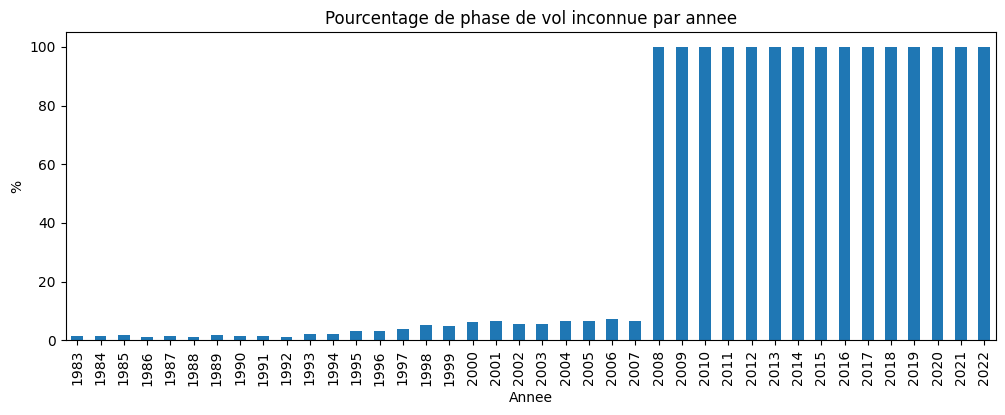

In [ ]:
# Broad.phase.of.flight : pourcentage de UNKNOWN par annee
annee = aviation_df["Event.Date"].dt.year
inconnu_phase = (aviation_df["Broad.phase.of.flight"] == "UNKNOWN").groupby(annee).mean() * 100

inconnu_phase.plot(kind="bar", figsize=(12, 4))
plt.title("Pourcentage de phase de vol inconnue par annee")
plt.ylabel("%")
plt.xlabel("Annee")
plt.show()

**Note :** a partir de 2008 la phase de vol n'est plus jamais remplie (100% UNKNOWN), avant c'etait moins de 10%. Ca doit venir d'un changement du formulaire de la NTSB. Donc si on etudie la phase de vol, il faudra utiliser seulement les accidents de 1983 a 2007.

### Suppression de colonnes
- inspectez le DataFrame et supprimez les colonnes qui contiennent trop de NaN

In [ ]:
aviation_df.isna().mean() * 100

,0
Event.Id,0.000000
Investigation.Type,0.000000
Accident.Number,0.000000
Event.Date,0.000000
Location,0.000000
Country,0.000000
Injury.Severity,0.000000
Aircraft.damage,0.000000
Aircraft.Category,0.000000
Make,0.000000


**Note :** les colonnes avec trop de NaN ont deja ete supprimees au debut. Il ne reste plus de NaN sauf dans `Destroyed`, c'est voulu (degats inconnus). On supprime juste les colonnes qui ne servent plus : `Make.Original` (seulement pour verifier le nettoyage), `Location` et `Country` qu'on n'utilise pas dans l'analyse.

In [ ]:
aviation_df = aviation_df.drop(columns=["Make.Original", "Location", "Country"])
print(aviation_df.shape)
aviation_df.columns

(56579, 26)


Index(['Event.Id', 'Investigation.Type', 'Accident.Number', 'Event.Date',
       'Injury.Severity', 'Aircraft.damage', 'Aircraft.Category', 'Make',
       'Model', 'Amateur.Built', 'Number.of.Engines', 'Engine.Type',
       'Purpose.of.flight', 'Total.Fatal.Injuries', 'Total.Serious.Injuries',
       'Total.Minor.Injuries', 'Total.Uninjured', 'Weather.Condition',
       'Broad.phase.of.flight', 'Uninjured.Imputed', 'Total.Occupants',
       'Fatal.Serious', 'Fatal.Serious.Rate', 'Severe.Accident', 'Destroyed',
       'Make.Model'],
      dtype='object')

### Enregistrer le DataFrame dans un fichier csv
- il est généralement utile d'enregistrer les données dans un fichier/sur un serveur une fois qu'elles sont suffisamment nettoyées ou à un état intermédiaire
- les données peuvent ensuite être chargées directement dans un autre notebook pour une analyse plus poussée
- cela contribue à garder vos notebooks et votre flux de travail lisibles, propres et modulaires

In [ ]:
aviation_df.to_csv("data/AviationData_clean.csv", index=False)
print("Fichier enregistre :", aviation_df.shape)

Fichier enregistre : (56579, 26)
